# Introduction

In the world of esports, reaction time is an important factor that can have a significant impact on player performance. Even small differences in reaction time can affect how quickly a player responds to events during gameplay. Many different factors, such as age, sleep, heart rate, play time, and environmental conditions, may influence a player's reaction time. By analyzing these factors, machine learning can be used to identify patterns and predict how quickly a player may react.

The goal of this project is to develop and evaluate machine learning models that predict esports players' reaction times based on various physiological, behavioral, and environmental metrics. The dataset used for this project is the **E-Sports Biometrics and Performance** dataset from Kaggle, which contains 250,000 observations of synthetic esports player data. The dataset includes variables such as age, game genre, sleep duration, energy drink consumption, heart rate, heart rate variability (HRV), and actions per minute (APM).

Two regression models will be implemented and compared: **Multiple Linear Regression** and **Random Forest Regression**. Multiple Linear Regression will be used to identify linear relationships between the independent variables and reaction time, while Random Forest Regression will be used to capture potentially more complex, nonlinear relationships. Both models will be trained using 80% of the dataset, with the remaining 20% reserved for testing.

The performance of these models will be evaluated using **Mean Absolute Error (MAE)**, **Root Mean Squared Error (RMSE)**, and **R² (Coefficient of Determination)**. These metrics will help determine how accurately each model predicts reaction time and which approach performs better. Ultimately, this project aims to explore the relationships between player metrics and reaction time while comparing the effectiveness of two different regression techniques.

In [1]:
#Imports
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import sklearn

from sklearn.model_selection import train_test_split
#import additional sklearn modules as needed

#import models
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

#import metrics
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, root_mean_squared_error

,Player_ID,Age,Game_Genre,PlayTime_Hours,Sleep_Hours,Energy_Drinks,Screen_Brightness,Blue_Light_Filter,APM,Heart_Rate_BPM,HRV_Score,Reaction_Time_ms,Match_Outcome
0,PL_000001,24,FPS,1.41,8.88,0,43.4,Yes,107,78,95.02,268.96,Loss
1,PL_000002,22,FPS,4.43,7.45,2,88.0,Yes,110,102,82.92,281.90,Win
2,PL_000003,25,Battle Royale,3.75,8.10,1,24.8,Yes,152,96,89.13,288.57,Win
3,PL_000004,29,FPS,1.76,6.69,0,80.2,No,151,65,80.41,279.76,Win
4,PL_000005,22,FPS,5.79,8.17,1,34.4,No,148,95,95.71,229.62,Loss


Exploratory Data Analysis (EDA):
Dataset Overview:
<class 'pandas.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 13 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   Player_ID          250000 non-null  str    
 1   Age                250000 non-null  int64  
 2   Game_Genre         250000 non-null  str    
 3   PlayTime_Hours     250000 non-null  float64
 4   Sleep_Hours        250000 non-null  float64
 5   Energy_Drinks      250000 non-null  int64  
 6   Screen_Brightness  237452 non-null  float64
 7   Blue_Light_Filter  250000 non-null  str    
 8   APM                250000 non-null  int64  
 9   Heart_Rate_BPM     250000 non-null  int64  
 10  HRV_Score          245066 non-null  float64
 11  Reaction_Time_ms   250000 non-null  float64
 12  Match_Outcome      250000 non-null  str    
dtypes: float64(5), int64(4), str(4)
memory usage: 29.6 MB


None

Statistical Summary:


,Age,PlayTime_Hours,Sleep_Hours,Energy_Drinks,Screen_Brightness,APM,Heart_Rate_BPM,HRV_Score,Reaction_Time_ms
count,250000.000000,250000.000000,250000.000000,250000.000000,237452.000000,250000.000000,250000.000000,245066.000000,250000.000000
mean,22.588136,2.527753,6.500900,0.917720,54.918735,204.076168,84.062784,87.479087,262.900538
std,3.829706,2.358799,1.495851,1.045559,25.965989,77.004233,9.670229,11.063101,19.096927
min,16.000000,0.500000,2.000000,0.000000,10.000000,30.000000,60.000000,25.510000,175.170000
25%,20.000000,0.720000,5.490000,0.000000,32.500000,143.000000,77.000000,80.590000,249.930000
50%,23.000000,1.730000,6.500000,1.000000,54.900000,192.000000,84.000000,89.190000,262.590000
75%,25.000000,3.470000,7.510000,1.000000,77.400000,263.000000,90.000000,97.260000,275.600000
max,40.000000,12.000000,11.000000,4.000000,100.000000,563.000000,129.000000,100.000000,355.470000


Data Types:


Player_ID                str
Age                    int64
Game_Genre               str
PlayTime_Hours       float64
Sleep_Hours          float64
Energy_Drinks          int64
Screen_Brightness    float64
Blue_Light_Filter        str
APM                    int64
Heart_Rate_BPM         int64
HRV_Score            float64
Reaction_Time_ms     float64
Match_Outcome            str
dtype: object

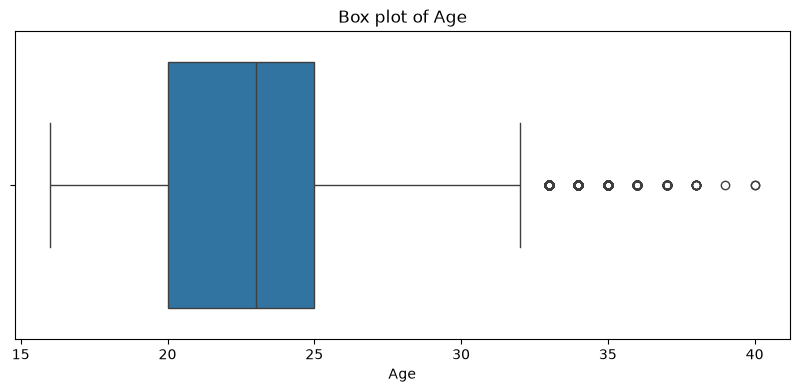

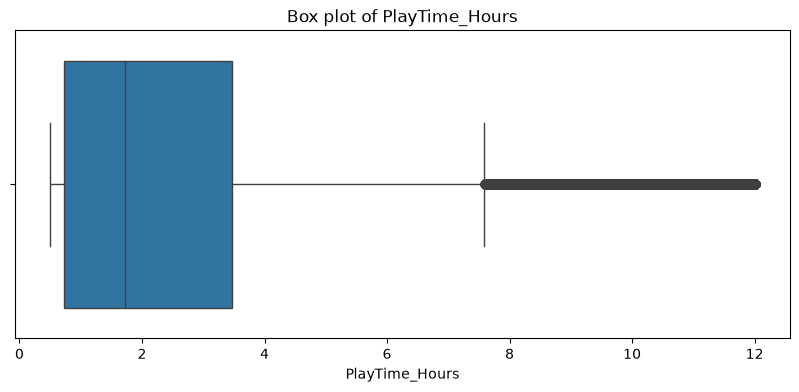

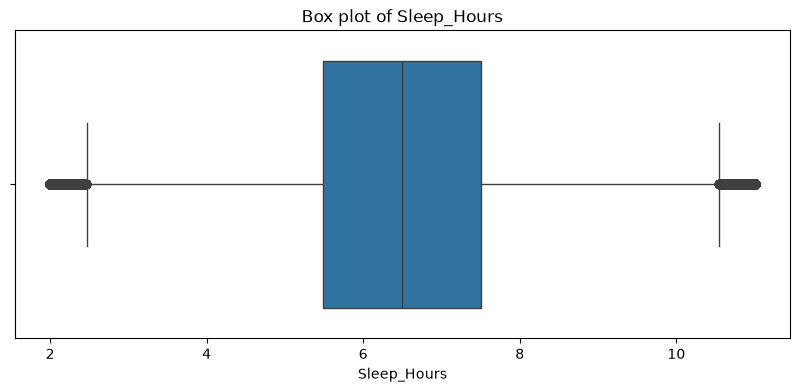

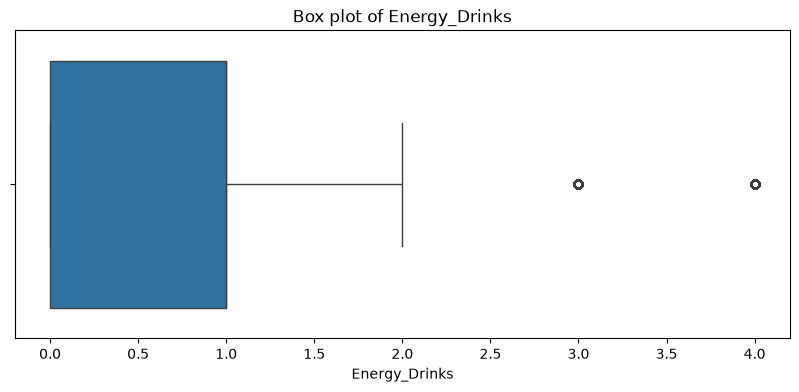

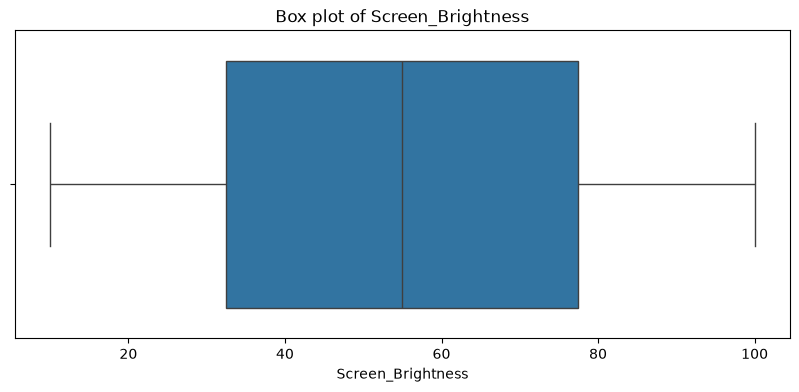

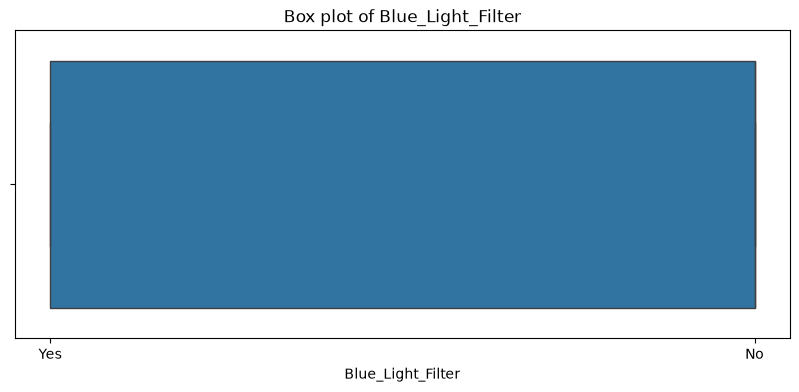

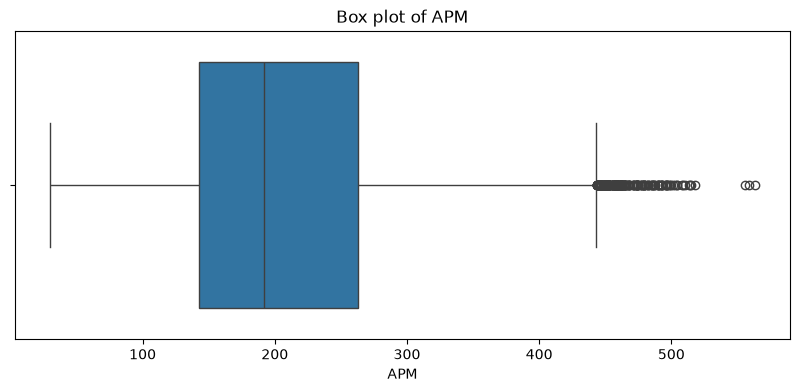

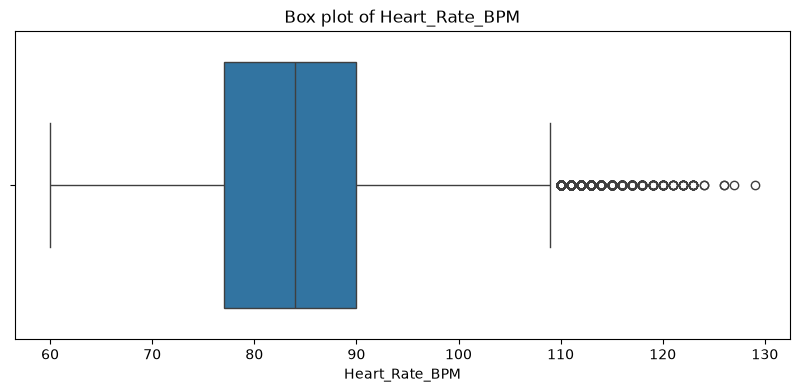

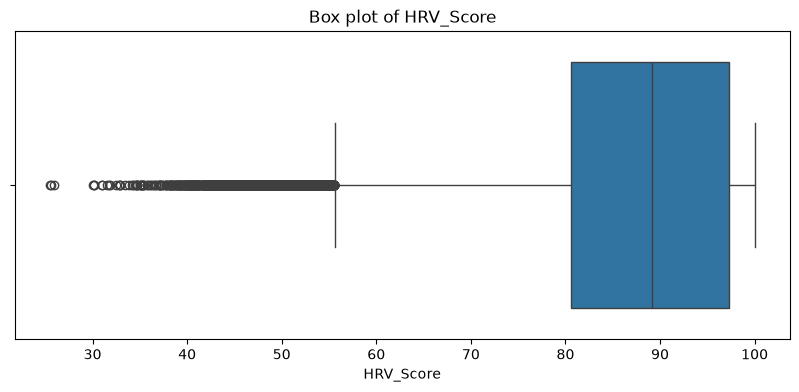

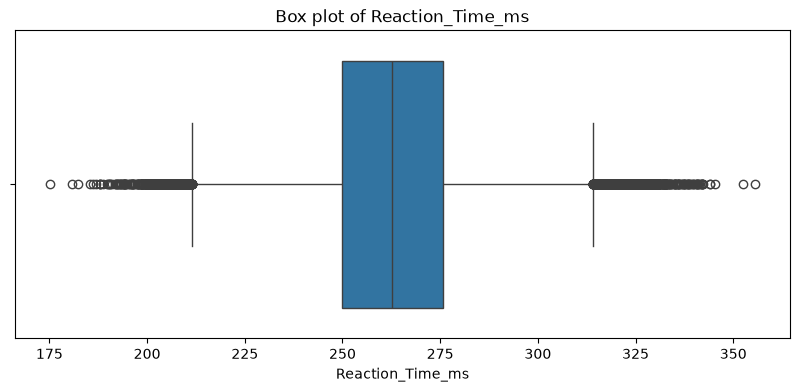

Changing data types of relevant columns...


Player_ID                str
Age                    int64
Game_Genre               str
PlayTime_Hours       float64
Sleep_Hours          float64
Energy_Drinks          int64
Screen_Brightness    float64
Blue_Light_Filter      int64
APM                    int64
Heart_Rate_BPM         int64
HRV_Score            float64
Reaction_Time_ms     float64
Match_Outcome            str
dtype: object

,Column,Outliers
0,Age,1527
1,PlayTime_Hours,12054
2,Sleep_Hours,1802
3,Energy_Drinks,24939
4,Screen_Brightness,0
5,Blue_Light_Filter,0
6,APM,221
7,Heart_Rate_BPM,1412
8,HRV_Score,2386
9,Reaction_Time_ms,1927


Outliers have been counted and displayed for each relevant column.


,Age,Game_Genre,PlayTime_Hours,Sleep_Hours,Energy_Drinks,Screen_Brightness,Blue_Light_Filter,APM,Heart_Rate_BPM,HRV_Score,Reaction_Time_ms
0,24,FPS,1.41,8.88,0,43.4,1,107,78,95.02,268.96
1,22,FPS,4.43,7.45,2,88.0,1,110,102,82.92,281.90
2,25,Battle Royale,3.75,8.10,1,24.8,1,152,96,89.13,288.57
3,29,FPS,1.76,6.69,0,80.2,0,151,65,80.41,279.76
4,22,FPS,5.79,8.17,1,34.4,0,148,95,95.71,229.62


,Missing Values,Percentage
Age,0,0.0000
Game_Genre,0,0.0000
PlayTime_Hours,0,0.0000
Sleep_Hours,0,0.0000
Energy_Drinks,0,0.0000
Screen_Brightness,12548,5.0192
Blue_Light_Filter,0,0.0000
APM,0,0.0000
Heart_Rate_BPM,0,0.0000
HRV_Score,4934,1.9736


... (11 outputs left out)

np.int64(0)

No duplicate rows found.


'Final count of rows and columns after cleaning:'

,Columns,Rows
0,11,232793


In [2]:
#import the dataset
df = pd.read_csv("/home/lavig/cs746/Project/esports_gaming_biometrics_250k.csv")
display(df.head())

#EDA
print("Exploratory Data Analysis (EDA):")
print("Dataset Overview:")
display(df.info())
print("Statistical Summary:")
display(df.describe())
#Data types
print("Data Types:")
display(df.dtypes)
#Now to remove the columns we don't want in the dataset
#Keeping age, playtime, sleep, energy drinks, brightness, apm, blue light filter, heart rate, and hrv - Keeping the target variable for now to split after cleaning
columns_to_keep = ["Age", "Game_Genre", "PlayTime_Hours", "Sleep_Hours", "Energy_Drinks", "Screen_Brightness", "Blue_Light_Filter", "APM", "Heart_Rate_BPM", "HRV_Score", "Reaction_Time_ms"]

#Box plot for visualizing outliers in the relevant columns
import matplotlib.pyplot as plt
import seaborn as sns

for column in columns_to_keep:
    if column != "Game_Genre":  # Skip categorical column
        plt.figure(figsize=(10, 4))
        sns.boxplot(x=df[column])
        plt.title(f"Box plot of {column}")
        plt.show()

#Change the types of relevant columns to appropriate data types
print("Changing data types of relevant columns...")
df["Age"] = df["Age"].astype(int)
df["PlayTime_Hours"] = df["PlayTime_Hours"].astype(float)
df["Sleep_Hours"] = df["Sleep_Hours"].astype(float)
df["Energy_Drinks"] = df["Energy_Drinks"].astype(int)
df["Screen_Brightness"] = df["Screen_Brightness"].astype(float)
df["Blue_Light_Filter"] = df["Blue_Light_Filter"].map({"Yes": 1, "No": 0})
df["APM"] = df["APM"].astype(int)
df["Heart_Rate_BPM"] = df["Heart_Rate_BPM"].astype(int)
df["HRV_Score"] = df["HRV_Score"].astype(float)
df["Reaction_Time_ms"] = df["Reaction_Time_ms"].astype(float)

#Verify the changes in data types
display(df.dtypes)

#Check for outliers in the relevant columns
outliers_count = {}
for column in columns_to_keep:
    if column != "Game_Genre":  # Skip categorical column
        Q1 = df[column].quantile(0.25)
        Q3 = df[column].quantile(0.75)
        IQR = Q3 - Q1
        outliers = df[(df[column] < (Q1 - 1.5 * IQR)) | (df[column] > (Q3 + 1.5 * IQR))]
        outliers_count[column] = len(outliers)
display(pd.DataFrame(list(outliers_count.items()), columns=["Column", "Outliers"]))
print("Outliers have been counted and displayed for each relevant column.")

X = df[columns_to_keep]
display(X.head())
#Check for missing values in the relevant columns
missing_values = pd.DataFrame(X.isnull().sum(), columns=['Missing Values'])
missing_values['Percentage'] = (missing_values['Missing Values'] / len(X)) * 100
display(missing_values)

#Remove rows with missing values in the relevant columns
X = X.dropna()
display("Total count of rows and columns after removing missing values:")
display(pd.DataFrame({"Columns": [X.shape[1]], "Rows": [X.shape[0]]}))

#Check for duplicate rows after removing missing values
display("Duplicate rows after removing missing values:")
display(X.duplicated().sum())
if X.duplicated().sum() > 0:
    print("Removing duplicate rows...")
    X = X.drop_duplicates()
    display(pd.DataFrame({"Columns": [X.shape[1]], "Rows": [X.shape[0]]}))
else:
    print("No duplicate rows found.")

display("Final count of rows and columns after removing duplicates:")
display(pd.DataFrame({"Columns": [X.shape[1]], "Rows": [X.shape[0]]}))

#Display the first few rows of the cleaned dataset
display(X.head())

#Check the data types of the cleaned dataset
display(X.dtypes)

#Check for any remaining missing values in the cleaned dataset
missing_values_cleaned = pd.DataFrame(X.isnull().sum(), columns=['Missing Values'])
missing_values_cleaned['Percentage'] = (missing_values_cleaned['Missing Values'] / len(X)) * 100
display(missing_values_cleaned)
#Check for duplicate rows in the cleaned dataset
display("Duplicate rows in the cleaned dataset:")
display(X.duplicated().sum())
if X.duplicated().sum() > 0:
    print("Removing duplicate rows...")
    X = X.drop_duplicates()
    display(pd.DataFrame({"Columns": [X.shape[1]], "Rows": [X.shape[0]]}))
else:
    print("No duplicate rows found.")
display("Final count of rows and columns after cleaning:")
display(pd.DataFrame({"Columns": [X.shape[1]], "Rows": [X.shape[0]]}))

## Data Cleaning and Exploratory Data Analysis

First, I loaded the dataset with pandas and displayed the first few rows to make sure it loaded right. Then I did some EDA to get a feel for the data by looking at the general info, the summary statistics, and the data types of each column. The dataset starts out with 250,000 rows and 13 columns.

Next, I picked which columns to use for predicting reaction time. I dropped Player ID and Match Outcome. Player ID is just an identifier, and match outcome isn't something we would know before a player's reaction time is measured, so neither one helps the model. This left 11 columns, which includes the target, Reaction_Time_ms.

After that, I made boxplots of the numerical columns to see how the data is distributed and used the IQR method to count the outliers in each one. I decided to keep the outliers in for now. A lot of them are probably real differences between players, not bad data, so removing them could hurt the results.

Then I fixed the data types so the models can use them. Most columns became ints or floats, and Blue Light Filter was changed to binary, with Yes as 1 and No as 0.

With the types fixed, I checked for missing values and calculated the percentage missing in each column. Screen_Brightness is missing 12,548 values (5.02%) and HRV_Score is missing 4,934 (1.97%). Every other column has none. I chose to remove the rows with missing values instead of filling them in, since with 250,000 rows there is still plenty of data left for training and testing. Some rows were missing both values, which is why the 17,207 rows removed (6.88%) is less than the two counts added together. That leaves 232,793 rows. I then checked for duplicates and found 0, so nothing else needed to be removed.

Finally, I double checked that no missing values or duplicates were left in the cleaned dataset. I decided to keep Reaction_Time_ms in the dataset for now, since I still want to do some more preprocessing and look at how the different variables relate to reaction time before separating the independent variables from the target.

## What We Have Now

- 232,793 rows, about 93% of the original data
- 10 independent variables and 1 target variable (Reaction_Time_ms)
- No missing values and no duplicates
- Reaction_Time_ms is still included in the cleaned dataset

The initial data cleaning is finished. Next, I'll look at the correlations between the different variables, handle the categorical data, and then separate the features and target variable before training the regression models.

Unique Game Genres:


,Game Genre
0,FPS
1,Battle Royale
2,MOBA
3,Fighting


Game Genre Counts:


,Game_Genre,count
0,MOBA,99887
1,FPS,87708
2,Battle Royale,37375
3,Fighting,25030


Total Unique Genres: 4
Columns in the X dataset:


,Column Name
0,Age
1,Game_Genre
2,PlayTime_Hours
3,Sleep_Hours
4,Energy_Drinks
5,Screen_Brightness
6,Blue_Light_Filter
7,APM
8,Heart_Rate_BPM
9,HRV_Score


"Feature set after changing 'Game_Genre' to categorical:"

,Age,Game_Genre,PlayTime_Hours,Sleep_Hours,Energy_Drinks,Screen_Brightness,Blue_Light_Filter,APM,Heart_Rate_BPM,HRV_Score,Reaction_Time_ms
0,24,FPS,1.41,8.88,0,43.4,1,107,78,95.02,268.96
1,22,FPS,4.43,7.45,2,88.0,1,110,102,82.92,281.90
2,25,Battle Royale,3.75,8.10,1,24.8,1,152,96,89.13,288.57
3,29,FPS,1.76,6.69,0,80.2,0,151,65,80.41,279.76
4,22,FPS,5.79,8.17,1,34.4,0,148,95,95.71,229.62


Data types after changing 'Game_Genre' to categorical:


Age                     int64
Game_Genre           category
PlayTime_Hours        float64
Sleep_Hours           float64
Energy_Drinks           int64
Screen_Brightness     float64
Blue_Light_Filter       int64
APM                     int64
Heart_Rate_BPM          int64
HRV_Score             float64
Reaction_Time_ms      float64
dtype: object

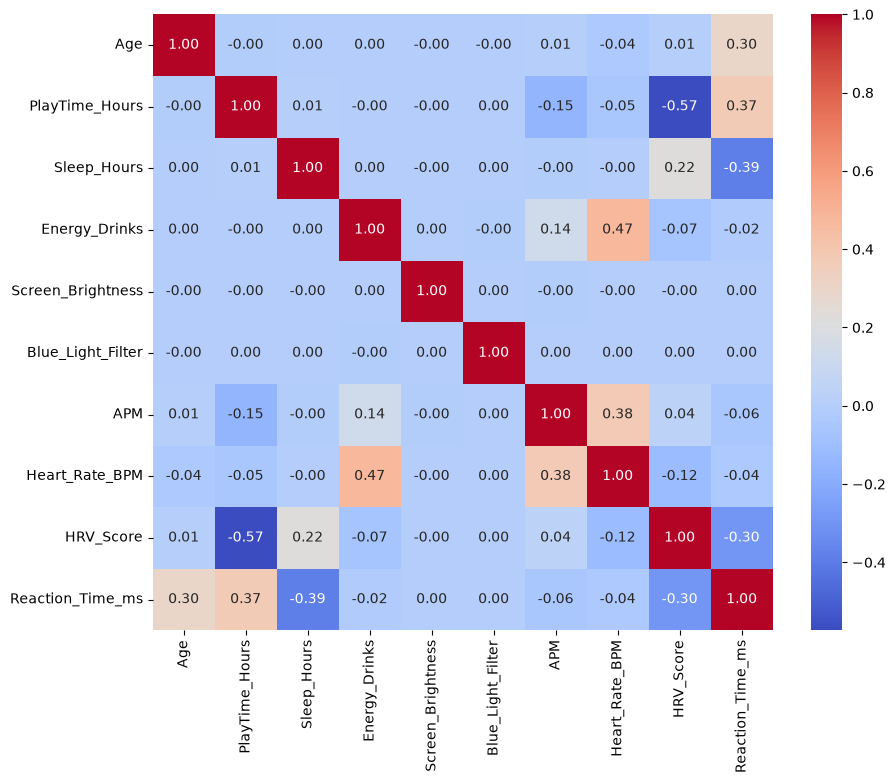

'Feature set after dropping target variable:'

,Age,Game_Genre,PlayTime_Hours,Sleep_Hours,Energy_Drinks,Screen_Brightness,Blue_Light_Filter,APM,Heart_Rate_BPM,HRV_Score
0,24,FPS,1.41,8.88,0,43.4,1,107,78,95.02
1,22,FPS,4.43,7.45,2,88.0,1,110,102,82.92
2,25,Battle Royale,3.75,8.10,1,24.8,1,152,96,89.13
3,29,FPS,1.76,6.69,0,80.2,0,151,65,80.41
4,22,FPS,5.79,8.17,1,34.4,0,148,95,95.71


'Target variable:'

,Reaction_Time_ms
0,268.96
1,281.90
2,288.57
3,279.76
4,229.62


In [3]:
# Display all unique game genres in a nice table
print("Unique Game Genres:")
display(pd.DataFrame(df["Game_Genre"].unique(), columns=["Game Genre"]))

# Display the number of players in each genre
print("Game Genre Counts:")
display(df["Game_Genre"].value_counts().reset_index())

# Display the total number of unique genres
print("Total Unique Genres:", df["Game_Genre"].nunique())

# Columns in the X dataset
print("Columns in the X dataset:")
display(pd.DataFrame(X.columns, columns=["Column Name"]))
# Change the "Game_Genre" column to a categorical type
X["Game_Genre"] = X["Game_Genre"].astype("category")
display("Feature set after changing 'Game_Genre' to categorical:")
display(X.head())
print("Data types after changing 'Game_Genre' to categorical:")
display(X.dtypes)

# Correlation matrix for numerical features
numerical_features = X.select_dtypes(exclude=["category"])
corr_matrix = numerical_features.corr()
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm")
plt.show()

# Split the dataset into features and target variable
y = X["Reaction_Time_ms"]
X = X.drop(columns=["Reaction_Time_ms"])
display("Feature set after dropping target variable:")
display(pd.DataFrame(X.head(), columns=X.columns))
display("Target variable:")
display(pd.DataFrame(y.head(), columns=["Reaction_Time_ms"]))

## Feature Preparation and Correlation Analysis

After cleaning the dataset, I started preparing the features for the regression models. First, I displayed all the unique game genres and counted how many observations were in each one. I also checked the total number of different genres and displayed the columns that were still in the cleaned dataset.

Next, I changed Game_Genre to a categorical data type. Since the game genres are different categories rather than numerical values, I wanted to make sure they were stored correctly. I decided to leave the genres as categories for now and handle the one-hot encoding later when preparing the training and testing data.

After that, I created a correlation matrix using the numerical columns to see how the different player metrics relate to each other and to reaction time. I used Pearson correlation, which gives values between -1 and 1. Positive values mean the variables tend to increase together, while negative values mean that as one increases, the other tends to decrease.

Looking at the results, Sleep_Hours had the strongest correlation with reaction time at -0.39, meaning players who got more sleep tended to have faster reaction times. PlayTime_Hours had a correlation of 0.37, showing that more playtime was associated with slower reaction times. Age had a correlation of 0.30, while HRV_Score was -0.30.

Some of the other variables had very weak correlations with reaction time. APM was -0.06, Heart_Rate_BPM was -0.04, and Energy_Drinks was -0.02. Screen_Brightness and Blue_Light_Filter were both close to zero. I decided to keep these variables for now because they could still have nonlinear relationships that Random Forest might be able to identify.

I also noticed some correlations between the independent variables. PlayTime_Hours and HRV_Score had a correlation of -0.57, while Energy_Drinks and Heart_Rate_BPM had a correlation of 0.47. These are worth keeping in mind when comparing the models later.

Finally, I separated Reaction_Time_ms from the rest of the dataset. I stored the independent variables in **X** and the target variable in **y**. This leaves the features and target ready for the train-test split and the remaining preprocessing steps.

'Training feature set:'

,Age,Game_Genre,PlayTime_Hours,Sleep_Hours,Energy_Drinks,Screen_Brightness,Blue_Light_Filter,APM,Heart_Rate_BPM,HRV_Score
163291,20,FPS,0.50,7.52,3,41.0,1,164,89,100.00
34488,16,MOBA,1.05,5.86,0,11.5,0,259,65,100.00
51303,26,Fighting,2.27,5.99,0,43.5,0,295,93,96.94
73087,25,MOBA,1.39,7.47,3,79.2,1,240,97,100.00
133273,28,FPS,2.93,8.87,0,56.4,0,151,60,100.00


'Training target variable:'

,Reaction_Time_ms
163291,285.78
34488,237.92
51303,278.80
73087,246.24
133273,266.71


'Testing feature set:'

,Age,Game_Genre,PlayTime_Hours,Sleep_Hours,Energy_Drinks,Screen_Brightness,Blue_Light_Filter,APM,Heart_Rate_BPM,HRV_Score
83597,18,MOBA,7.76,8.13,0,11.4,0,151,80,80.89
247259,24,MOBA,0.50,7.39,2,67.6,0,310,92,85.83
226037,19,FPS,2.12,8.16,2,44.7,1,150,93,83.19
115232,22,FPS,8.79,6.31,1,58.9,0,93,84,71.91
105967,18,MOBA,4.84,7.20,3,50.1,0,210,108,75.07


'Testing target variable:'

,Reaction_Time_ms
83597,257.20
247259,246.80
226037,262.65
115232,305.02
105967,277.84


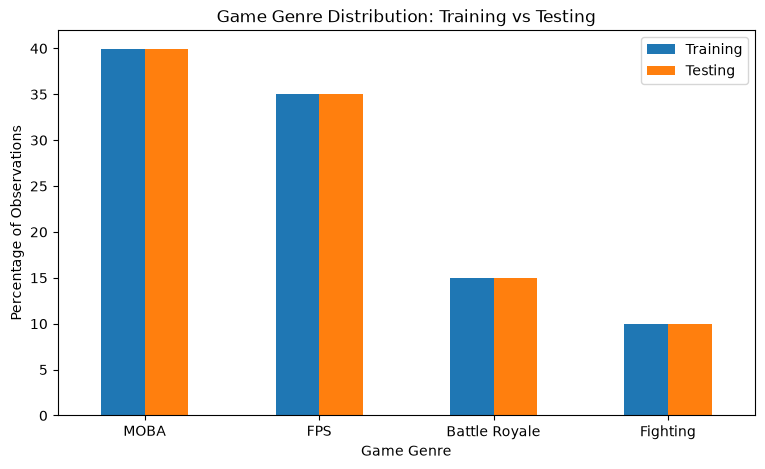

'Training set after one-hot encoding:'

,Age,PlayTime_Hours,Sleep_Hours,Energy_Drinks,Screen_Brightness,Blue_Light_Filter,APM,Heart_Rate_BPM,HRV_Score,Game_Genre_FPS,Game_Genre_Fighting,Game_Genre_MOBA
163291,20,0.50,7.52,3,41.0,1,164,89,100.00,True,False,False
34488,16,1.05,5.86,0,11.5,0,259,65,100.00,False,False,True
51303,26,2.27,5.99,0,43.5,0,295,93,96.94,False,True,False
73087,25,1.39,7.47,3,79.2,1,240,97,100.00,False,False,True
133273,28,2.93,8.87,0,56.4,0,151,60,100.00,True,False,False


'Testing feature set after one-hot encoding:'

,Age,PlayTime_Hours,Sleep_Hours,Energy_Drinks,Screen_Brightness,Blue_Light_Filter,APM,Heart_Rate_BPM,HRV_Score,Game_Genre_FPS,Game_Genre_Fighting,Game_Genre_MOBA
83597,18,7.76,8.13,0,11.4,0,151,80,80.89,False,False,True
247259,24,0.50,7.39,2,67.6,0,310,92,85.83,False,False,True
226037,19,2.12,8.16,2,44.7,1,150,93,83.19,True,False,False
115232,22,8.79,6.31,1,58.9,0,93,84,71.91,True,False,False
105967,18,4.84,7.20,3,50.1,0,210,108,75.07,False,False,True


'Final feature set after one-hot encoding:'

,Age,PlayTime_Hours,Sleep_Hours,Energy_Drinks,Screen_Brightness,Blue_Light_Filter,APM,Heart_Rate_BPM,HRV_Score,Game_Genre_FPS,Game_Genre_Fighting,Game_Genre_MOBA
163291,20,0.50,7.52,3,41.0,1,164,89,100.00,True,False,False
34488,16,1.05,5.86,0,11.5,0,259,65,100.00,False,False,True
51303,26,2.27,5.99,0,43.5,0,295,93,96.94,False,True,False
73087,25,1.39,7.47,3,79.2,1,240,97,100.00,False,False,True
133273,28,2.93,8.87,0,56.4,0,151,60,100.00,True,False,False


... (6 outputs left out)

'Testing feature set shape:'

(46559, 12)

'Testing target variable shape:'

(46559,)

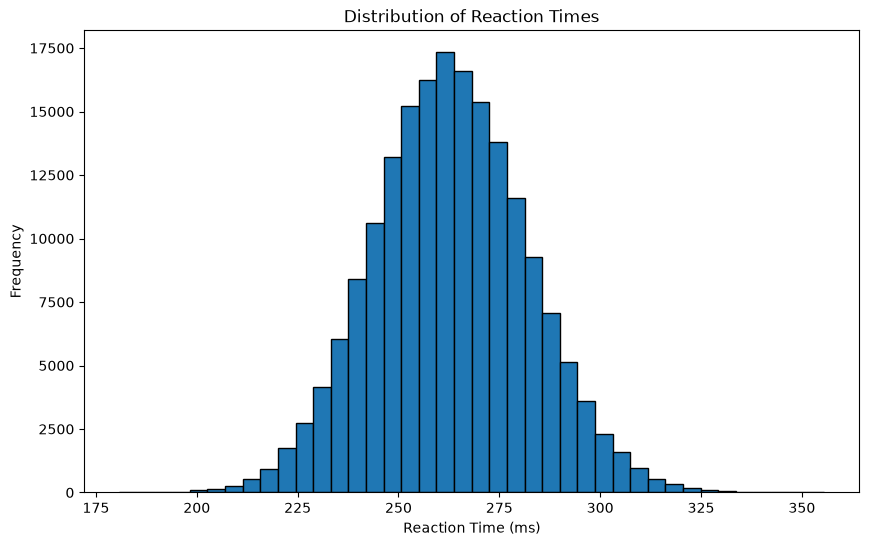

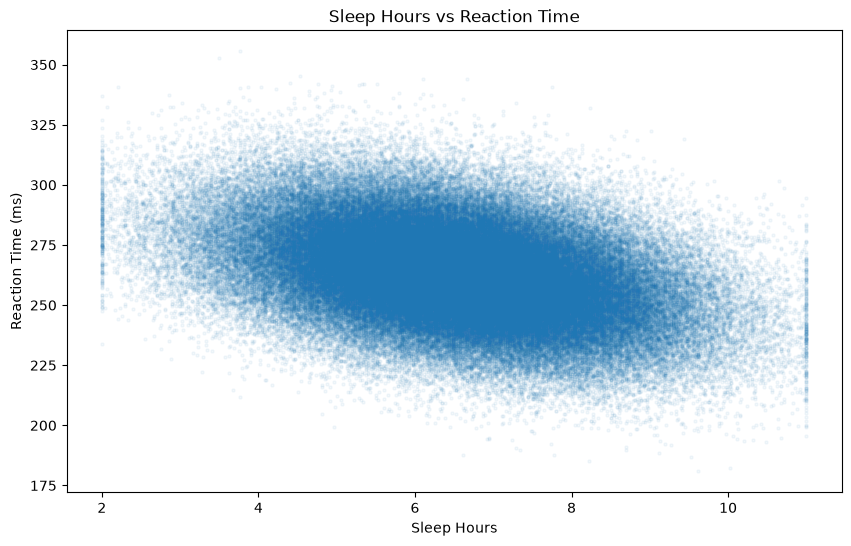

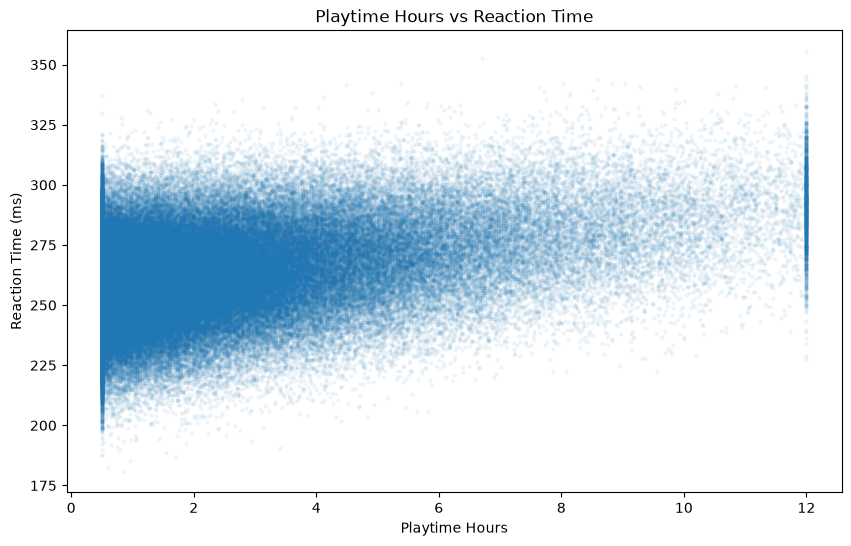

In [4]:
# Now the dataset is ready for model training and evaluation
# Split the one-hot encoded dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=X["Game_Genre"])
display("Training feature set:")
display(pd.DataFrame(X_train.head(), columns=X_train.columns))
display("Training target variable:")
display(pd.DataFrame(y_train.head(), columns=["Reaction_Time_ms"]))
display("Testing feature set:")
display(pd.DataFrame(X_test.head(), columns=X_test.columns))
display("Testing target variable:")
display(pd.DataFrame(y_test.head(), columns=["Reaction_Time_ms"]))

# Compare game genre distributions between training and testing sets
genre_distribution = pd.DataFrame({
    "Training": X_train["Game_Genre"].value_counts(normalize=True) * 100,
    "Testing": X_test["Game_Genre"].value_counts(normalize=True) * 100
})

genre_distribution.plot(kind="bar", figsize=(9, 5))
plt.title("Game Genre Distribution: Training vs Testing")
plt.xlabel("Game Genre")
plt.ylabel("Percentage of Observations")
plt.xticks(rotation=0)
plt.legend()
plt.show()

# One-hot encode categorical features
# Dropping first category to avoid multicollinearity
X_train = pd.get_dummies(X_train, drop_first=True)
display("Training set after one-hot encoding:")
display(pd.DataFrame(X_train.head(), columns=X_train.columns))
X_test = pd.get_dummies(X_test, drop_first=True)
display("Testing feature set after one-hot encoding:")
display(pd.DataFrame(X_test.head(), columns=X_test.columns))

# Final feature set after one-hot encoding
display("Final feature set after one-hot encoding:")
display(pd.DataFrame(X_train.head(), columns=X_train.columns))
display("Final testing feature set after one-hot encoding:")
display(pd.DataFrame(X_test.head(), columns=X_test.columns))

# Display the shapes of the training and testing sets
display("Training feature set shape:")
display(X_train.shape)
display("Training target variable shape:")
display(y_train.shape)
display("Testing feature set shape:")
display(X_test.shape)
display("Testing target variable shape:")
display(y_test.shape)

# Display the distribution of reaction times
plt.figure(figsize=(10, 6))
plt.hist(y_train, bins=40, edgecolor="black")
plt.title("Distribution of Reaction Times")
plt.xlabel("Reaction Time (ms)")
plt.ylabel("Frequency")
plt.show()

# Display relationship between sleep hours and reaction time
plt.figure(figsize=(10, 6))
plt.scatter(X_train["Sleep_Hours"], y_train, alpha=0.05, s=5)
plt.title("Sleep Hours vs Reaction Time")
plt.xlabel("Sleep Hours")
plt.ylabel("Reaction Time (ms)")
plt.show()

# Display relationship between playtime and reaction time
plt.figure(figsize=(10, 6))
plt.scatter(X_train["PlayTime_Hours"], y_train, alpha=0.05, s=5)
plt.title("Playtime Hours vs Reaction Time")
plt.xlabel("Playtime Hours")
plt.ylabel("Reaction Time (ms)")
plt.show()

## Train-Test Split, One-Hot Encoding, and Data Visualization

After preparing the features and target variable, I split the dataset into training and testing sets using an 80/20 split. I used a random state of 42 so the split would be reproducible. I also stratified the split using Game_Genre to make sure the proportions of the four game genres stayed approximately the same in both datasets.

To verify that the stratification worked, I created a bar chart comparing the percentage of observations in each genre between the training and testing sets. This allows me to check that both sets have similar distributions and that no genre is overrepresented or underrepresented compared to the original dataset.

Next, I performed one-hot encoding on Game_Genre for both the training and testing sets. Since game genres are categorical and don't have a numerical order, I needed to convert them into numerical features for the regression models. I used `drop_first=True` to remove one of the genre columns and avoid perfect multicollinearity in Multiple Linear Regression. The removed genre can still be identified when all the other genre columns are zero, so no information is lost.

After encoding, I displayed the final training and testing feature sets and checked their shapes to verify that the data was ready for model training.

I also created a histogram of Reaction_Time_ms using the training data to look at the distribution of reaction times. This helps me see how the values are spread out and whether there are any noticeable patterns or skewness in the target variable.

Finally, I created scatterplots comparing Sleep_Hours and PlayTime_Hours against Reaction_Time_ms. These two variables had some of the strongest correlations with reaction time in my earlier analysis, so I wanted to get a better look at their relationships. The scatterplots will help me see whether these relationships appear linear or if there are patterns that Random Forest Regression might be better at identifying.

With the data split, categorical features encoded, and additional visualizations completed, the dataset is ready for training and evaluating the Multiple Linear Regression and Random Forest Regression models.

,Evaluation Metrics,Value
0,Mean Squared Error,225.443605
1,Root Mean Squared Error,15.014780
2,Mean Absolute Error,11.964344
3,R^2 Score,0.382134


,Evaluation Metrics,Training,Testing
0,MSE,226.789051,225.443605
1,RMSE,15.059517,15.014780
2,MAE,12.015280,11.964344
3,R^2 Score,0.377008,0.382134


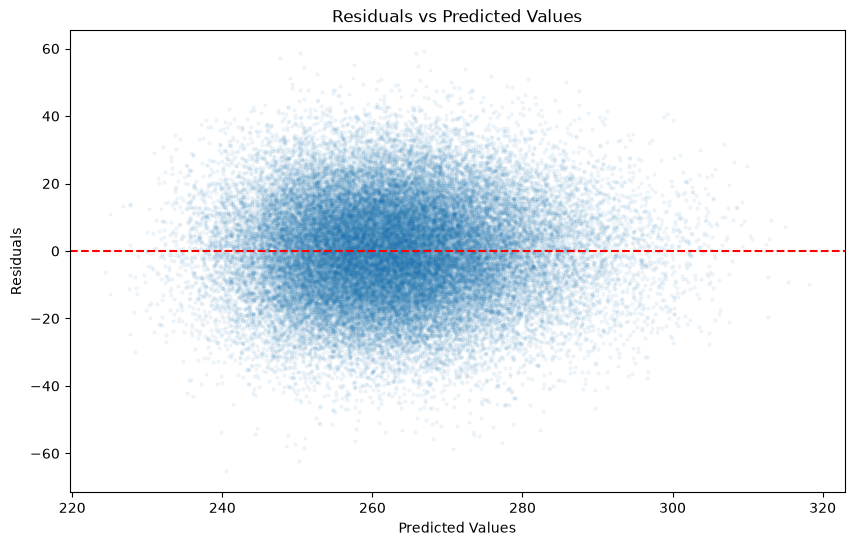

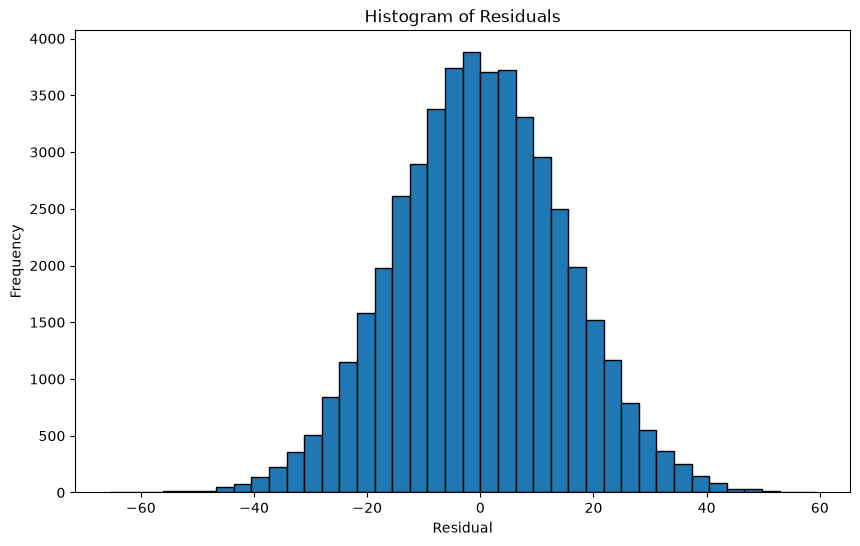

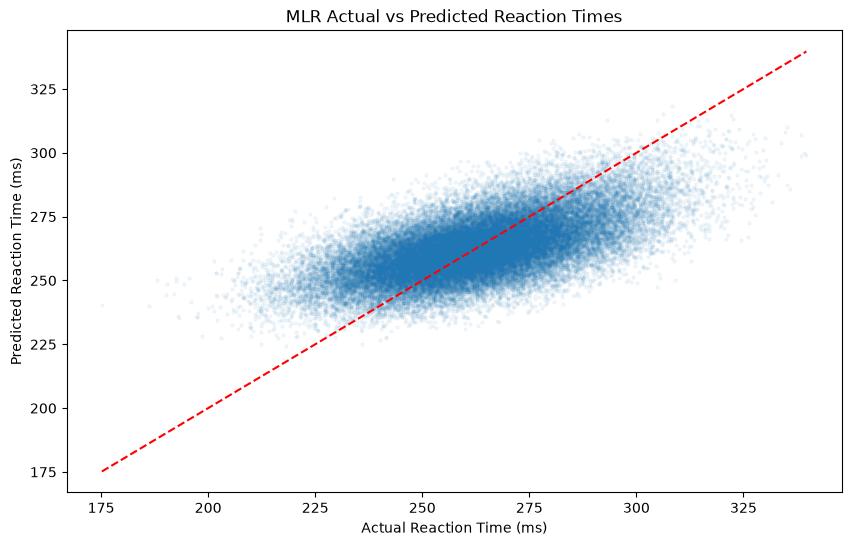

In [14]:
# The dataset has been split into training and testing sets, and one-hot encoding has been applied to categorical features. Now we can proceed with model training and evaluation.

# Start model training and evaluation
# Initialize and train a linear regression model
model = LinearRegression()
model.fit(X_train, y_train)

# Make predictions on the testing set
y_pred = model.predict(X_test)

# Evaluate the initial model
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

# Display evaluation metrics
display(pd.DataFrame({
    "Evaluation Metrics": [
        "Mean Squared Error",
        "Root Mean Squared Error",
        "Mean Absolute Error",
        "R^2 Score"
    ],
    "Value": [mse, rmse, mae, r2]
}))

# Evaluate MLR performance on training data
y_pred_train = model.predict(X_train)

# Calculate training evaluation metrics
mse_train = mean_squared_error(y_train, y_pred_train)
rmse_train = np.sqrt(mse_train)
mae_train = mean_absolute_error(y_train, y_pred_train)
r2_train = r2_score(y_train, y_pred_train)

# Compare training and testing performance
display(pd.DataFrame({
    "Evaluation Metrics": ["MSE", "RMSE", "MAE", "R^2 Score"],
    "Training": [mse_train, rmse_train, mae_train, r2_train],
    "Testing": [mse, rmse, mae, r2]
}))

# Display residuals
residuals = y_test - y_pred
plt.figure(figsize=(10, 6))
plt.scatter(y_pred, residuals, alpha=0.05, s=5)
plt.axhline(y=0, color='r', linestyle='--')
plt.title("Residuals vs Predicted Values")
plt.xlabel("Predicted Values")
plt.ylabel("Residuals")
plt.show()

# Histogram of residuals
plt.figure(figsize=(10, 6))
plt.hist(residuals, bins=40, edgecolor="black")
plt.title("Histogram of Residuals")
plt.xlabel("Residual")
plt.ylabel("Frequency")
plt.show()

# Compare actual and predicted reaction times
plt.figure(figsize=(10, 6))
plt.scatter(y_test, y_pred, alpha=0.05, s=5)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--"
)
plt.title("MLR Actual vs Predicted Reaction Times")
plt.xlabel("Actual Reaction Time (ms)")
plt.ylabel("Predicted Reaction Time (ms)")
plt.show()

## Multiple Linear Regression Baseline Model

After finishing the preprocessing and splitting the dataset into training and testing sets, I started by training a Multiple Linear Regression (MLR) model. I wanted to establish a baseline for predicting reaction times before trying to improve the model or comparing it against Random Forest Regression.

First, I initialized a LinearRegression model using Scikit-learn and trained it using X_train and y_train. Once the model was trained, I used X_test to predict reaction times and compared those predictions against the actual values in y_test.

I evaluated the model using Mean Squared Error (MSE), Root Mean Squared Error (RMSE), Mean Absolute Error (MAE), and R². The initial model produced the following results:

| Evaluation Metric | Result |
|---|---|
| Mean Squared Error (MSE) | 225.44 |
| Root Mean Squared Error (RMSE) | 15.01 ms |
| Mean Absolute Error (MAE) | 11.96 ms |
| R² Score | 0.3821 |

Looking at these results, the model was able to explain approximately 38.21% of the variation in reaction times. The MAE of 11.96 ms means that the model's predictions were off by about 12 milliseconds on average. The RMSE was slightly higher at 15.01 ms because it gives more weight to larger prediction errors.

Overfitting on the model here doesn't seem likely, as the R^2 scores are very close to each other between the metrics of the testing and training models.

After evaluating the model, I calculated the residuals by subtracting the predicted reaction times from the actual reaction times. I created a scatterplot of the residuals against the predicted values to see whether there were any noticeable patterns in the errors. The residuals were generally scattered around zero without any obvious curved patterns. This suggests that the model is capturing the main linear relationships reasonably well, although there were still some larger errors.

Next, I created a histogram of the residuals to examine how the prediction errors were distributed. This helps me see whether the residuals are centered around zero and whether the errors are approximately normally distributed.

Finally, I created an actual vs. predicted reaction time scatterplot. I added a diagonal reference line to represent perfect predictions, allowing me to see how closely the predicted values matched the actual reaction times. Looking at the graph, the model tended to overpredict players with faster reaction times and underpredict players with slower reaction times. The predictions were concentrated more toward the average rather than covering the full range of actual reaction times.

Overall, the baseline MLR model is able to identify some relationships between the player metrics and reaction time, but there is still a considerable amount of variation that it isn't explaining. I plan to use these results as a starting point for experimenting with improvements to the model and eventually comparing its performance against Random Forest Regression.

In [15]:
#Hyperparameter tuning for MLR
from sklearn.linear_model import Ridge, Lasso, ElasticNet
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

#Ridge regression pipeline
pipeline_ridge = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Ridge())
])

# alpha values to test
parameters_ridge = {
    "model__alpha": [0.01, 0.1, 1, 10, 100]
}

# Grid search for Ridge regression
grid_search = GridSearchCV(pipeline_ridge, parameters_ridge, cv=5, scoring="neg_mean_squared_error")
grid_search.fit(X_train, y_train)

# Best model and its parameters
best_model_ridge = grid_search.best_estimator_
display(pd.DataFrame({
    "Best Parameters - Ridge": [grid_search.best_params_]
}))

# Evaluate the best Ridge model on the test set
y_pred_ridge = best_model_ridge.predict(X_test)
mse_ridge = mean_squared_error(y_test, y_pred_ridge)
rmse_ridge = np.sqrt(mse_ridge)
mae_ridge = mean_absolute_error(y_test, y_pred_ridge)
r2_ridge = r2_score(y_test, y_pred_ridge)

display(pd.DataFrame({
    "Evaluation Metrics": [
        "Mean Squared Error",
        "Root Mean Squared Error",
        "Mean Absolute Error",
        "R^2 Score"
    ],
    "Value": [mse_ridge, rmse_ridge, mae_ridge, r2_ridge]
}))

# Now tune the Lasso model
pipeline_lasso = Pipeline([
    ("scaler", StandardScaler()),
    ("model", Lasso())
])

parameters_lasso = {
    "model__alpha": [0.01, 0.1, 1, 10, 100]
}

# Grid search for Lasso regression
grid_search = GridSearchCV(pipeline_lasso, parameters_lasso, cv=5, scoring="neg_mean_squared_error")
grid_search.fit(X_train, y_train)

# Best model and its parameters
best_model_lasso = grid_search.best_estimator_
display(pd.DataFrame({
    "Best Parameters - Lasso": [grid_search.best_params_]
}))

# Evaluate the best Lasso model on the test set
y_pred_best_lasso = best_model_lasso.predict(X_test)
mse_best_lasso = mean_squared_error(y_test, y_pred_best_lasso)
rmse_best_lasso = np.sqrt(mse_best_lasso)
mae_best_lasso = mean_absolute_error(y_test, y_pred_best_lasso)
r2_best_lasso = r2_score(y_test, y_pred_best_lasso)

display(pd.DataFrame({
    "Evaluation Metrics": [
        "Mean Squared Error",
        "Root Mean Squared Error",
        "Mean Absolute Error",
        "R^2 Score"
    ],
    "Value": [mse_best_lasso, rmse_best_lasso, mae_best_lasso, r2_best_lasso]
}))

# Now tune the ElasticNet model
pipeline_elastic = Pipeline([
    ("scaler", StandardScaler()),
    ("model", ElasticNet())
])

parameters_elastic = {
    "model__alpha": [0.01, 0.1, 1, 10, 100],
    "model__l1_ratio": [0.1, 0.5, 0.7, 0.9, 1.0]
}

# Grid search for ElasticNet regression
grid_search = GridSearchCV(pipeline_elastic, parameters_elastic, cv=5, scoring="neg_mean_squared_error")
grid_search.fit(X_train, y_train)

# Best model and its parameters
best_model_elastic = grid_search.best_estimator_
display(pd.DataFrame({
    "Best Parameters - ElasticNet": [grid_search.best_params_]
}))

# Evaluate the best ElasticNet model on the test set
y_pred_best_elastic = best_model_elastic.predict(X_test)
mse_best_elastic = mean_squared_error(y_test, y_pred_best_elastic)
rmse_best_elastic = np.sqrt(mse_best_elastic)
mae_best_elastic = mean_absolute_error(y_test, y_pred_best_elastic)
r2_best_elastic = r2_score(y_test, y_pred_best_elastic)

display(pd.DataFrame({
    "Evaluation Metrics": [
        "Mean Squared Error",
        "Root Mean Squared Error",
        "Mean Absolute Error",
        "R^2 Score"
    ],
    "Value": [mse_best_elastic, rmse_best_elastic, mae_best_elastic, r2_best_elastic]
}))

,Best Parameters - Ridge
0,{'model__alpha': 10}


,Evaluation Metrics,Value
0,Mean Squared Error,225.443739
1,Root Mean Squared Error,15.014784
2,Mean Absolute Error,11.964349
3,R^2 Score,0.382134


,Best Parameters - Lasso
0,{'model__alpha': 0.01}


,Evaluation Metrics,Value
0,Mean Squared Error,225.450613
1,Root Mean Squared Error,15.015013
2,Mean Absolute Error,11.964540
3,R^2 Score,0.382115


,Best Parameters - ElasticNet
0,"{'model__alpha': 0.01, 'model__l1_ratio': 1.0}"


,Evaluation Metrics,Value
0,Mean Squared Error,225.450613
1,Root Mean Squared Error,15.015013
2,Mean Absolute Error,11.964540
3,R^2 Score,0.382115


## Multiple Linear Regression Hyperparameter Tuning

After evaluating the baseline Multiple Linear Regression model, I wanted to see if I could improve its performance by using regularization. I decided to test three different regression methods: Ridge, Lasso, and Elastic Net. These methods are similar to regular Linear Regression, but they add penalties to the model's coefficients to help reduce overfitting.

First, I used StandardScaler to scale the features before training each model. Since the different player metrics have different ranges, I wanted to make sure that the regularization wasn't affected by the scale of the variables. I used a Pipeline to combine the scaling and regression steps so that the scaling would be handled correctly during training and cross-validation.

For the hyperparameter tuning, I used GridSearchCV with 5-fold cross-validation. This allowed me to test different alpha values and determine which one performed the best. I tested alpha values of 0.01, 0.1, 1, 10, and 100 for each model. I used negative Mean Squared Error as the scoring method, so GridSearchCV would select the parameters that produced the lowest average MSE.

I started with Ridge Regression, which uses L2 regularization to reduce the size of the coefficients without normally eliminating features completely. The best alpha value was 10. After evaluating the tuned model on the testing dataset, the results were almost identical to the original MLR model.

Next, I tested Lasso Regression, which uses L1 regularization. Unlike Ridge, Lasso can reduce some coefficients to zero, effectively removing those features from the model. The best alpha value was 0.01, which was the smallest value I tested. The results were also very close to the baseline model, although the prediction errors were slightly higher.

Finally, I tested Elastic Net Regression, which combines L1 and L2 regularization. Along with the alpha values, I tested different l1_ratio values of 0.1, 0.5, 0.7, 0.9, and 1.0. The l1_ratio controls how much of the regularization comes from Lasso compared to Ridge. The best parameters were an alpha of 0.01 and an l1_ratio of 1.0. This means the selected Elastic Net model was using L1 regularization, making it equivalent to Lasso with the same alpha.

After tuning each model, I evaluated them using the same MSE, RMSE, MAE, and R² metrics that I used for the baseline MLR model.

| Model | Best Alpha | RMSE | R² |
|---|---|---|---|
| Baseline MLR | N/A | 15.014780 | 0.382134 |
| Ridge | 10 | 15.014784 | 0.382134 |
| Lasso | 0.01 | 15.015013 | 0.382115 |
| Elastic Net | 0.01 | 15.015013 | 0.382115 |

Looking at these results, none of the regularization methods made a noticeable improvement over the original MLR model. Ridge performed almost exactly the same as the baseline, while Lasso and Elastic Net performed slightly worse. The differences were extremely small, so I don't think regularization had much of an effect on the model's performance.

This suggests that overfitting from large coefficients may not be a major issue with the original MLR model. It also shows that adjusting the regularization strength alone isn't enough to significantly improve the predictions.

Overall, I decided to keep the original MLR model as my baseline since the tuned models didn't provide any meaningful improvements. My next step will be to train a Random Forest Regression model to see whether it can capture relationships between the player metrics and reaction time that the linear models might be missing.

In [16]:
#Training the Forest Regression Model now
# Initialize the Random Forest Regressor
rf_model = RandomForestRegressor(random_state=42)

# Fit the model on the training data
rf_model.fit(X_train, y_train)

# Predict on the test set
y_pred_rf = rf_model.predict(X_test)

# Evaluate the model
mse_rf = mean_squared_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mse_rf)
mae_rf = mean_absolute_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)

display(pd.DataFrame({
    "Evaluation Metrics": [
        "Mean Squared Error",
        "Root Mean Squared Error",
        "Mean Absolute Error",
        "R^2 Score"
    ],
    "Value": [mse_rf, rmse_rf, mae_rf, r2_rf]
}))

# Evaluate Random Forest performance on training data
y_pred_rf_train = rf_model.predict(X_train)

# Calculate training evaluation metrics
mse_rf_train = mean_squared_error(y_train, y_pred_rf_train)
rmse_rf_train = np.sqrt(mse_rf_train)
mae_rf_train = mean_absolute_error(y_train, y_pred_rf_train)
r2_rf_train = r2_score(y_train, y_pred_rf_train)

# Compare training and testing performance
display(pd.DataFrame({
    "Evaluation Metrics": ["MSE", "RMSE", "MAE", "R^2 Score"],
    "Training": [mse_rf_train, rmse_rf_train, mae_rf_train, r2_rf_train],
    "Testing": [mse_rf, rmse_rf, mae_rf, r2_rf]
}))


,Evaluation Metrics,Value
0,Mean Squared Error,234.315098
1,Root Mean Squared Error,15.307354
2,Mean Absolute Error,12.197408
3,R^2 Score,0.357820


,Evaluation Metrics,Training,Testing
0,MSE,33.028250,234.315098
1,RMSE,5.747021,15.307354
2,MAE,4.546227,12.197408
3,R^2 Score,0.909271,0.357820


## Random Forest Regression Baseline Model

After training and evaluating the Multiple Linear Regression model, I moved on to training a Random Forest Regression model. I wanted to see whether a more complex model would be able to predict reaction times more accurately by capturing relationships between the player metrics that the MLR model might not have been able to identify.

First, I initialized a RandomForestRegressor using Scikit-learn with a random_state of 42 to keep the results reproducible. I kept the default hyperparameters for the initial model so that I could establish a baseline before attempting any tuning. I then trained the model using X_train and y_train. Once the model was trained, I used X_test to predict reaction times and compared those predictions against the actual values in y_test.

I evaluated the Random Forest model using the same metrics that I used for MLR: Mean Squared Error (MSE), Root Mean Squared Error (RMSE), Mean Absolute Error (MAE), and R². The initial model produced the following results:

| Evaluation Metric | Result |
|---|---|
| Mean Squared Error (MSE) | 234.32 |
| Root Mean Squared Error (RMSE) | 15.31 ms |
| Mean Absolute Error (MAE) | 12.20 ms |
| R² Score | 0.3578 |

Looking at these results, the Random Forest model was able to explain approximately 35.78% of the variation in reaction times. The MAE of 12.20 ms means that the model's predictions were off by about 12 milliseconds on average. The RMSE was slightly higher at 15.31 ms because it gives more weight to larger prediction errors.

Comparing these results against my baseline MLR model, the Random Forest actually performed slightly worse. The MLR model had an RMSE of 15.01 ms and an R² of 0.3821, meaning that it was able to explain slightly more of the variation in reaction times. I found this interesting because I expected Random Forest to potentially perform better due to its ability to capture more complex relationships between the variables.

After evaluating the model on the testing dataset, I also wanted to check whether the Random Forest was overfitting. To do this, I used the trained model to predict reaction times on X_train and compared the training evaluation metrics against the testing metrics.

| Evaluation Metric | Training | Testing |
|---|---|---|
| Mean Squared Error (MSE) | 33.03 | 234.32 |
| Root Mean Squared Error (RMSE) | 5.75 ms | 15.31 ms |
| Mean Absolute Error (MAE) | 4.55 ms | 12.20 ms |
| R² Score | 0.9093 | 0.3578 |

Looking at these results, there is a significant difference between the training and testing performance. The model was able to explain approximately 90.93% of the variation in the training data, but only 35.78% in the testing data. The training RMSE was also much lower at 5.75 ms compared to 15.31 ms on the testing dataset.

This suggests that the Random Forest model is overfitting the training data. It appears to be learning the training observations very well, but it isn't able to generalize those patterns as effectively to new data. This could be because the default Random Forest settings allow the individual decision trees to grow too complex, causing them to learn noise or patterns that aren't useful for predicting new observations.

This is also different from what I observed with the MLR model. The MLR training and testing R² scores were approximately 0.3770 and 0.3821, which were very close to each other. This suggests that the MLR model was generalizing much better, even though it wasn't able to explain as much variation in the training data as Random Forest.

Overall, the baseline Random Forest Regression model performed slightly worse than the MLR model and showed clear signs of overfitting. However, I don't think this necessarily means that Random Forest is a worse choice for predicting reaction times. Since I used the default hyperparameters, there may be opportunities to improve its performance by reducing the complexity of the individual trees.

My next step will be to experiment with hyperparameter tuning, particularly max_depth, min_samples_split, and min_samples_leaf, to see whether I can reduce the overfitting and improve the model's performance on unseen data.